# 4. Area-of-interest volumetrics with sequential Gaussian simulation

Notebooks 1-3 use the kriged map for OOIP. This notebook adds two things:

- **Simulation.** Kriging gives the best single estimate of porosity and honours the global mean, but it smooths: the
  porosity distribution of a kriged map is too narrow (regression to the mean). Sequential Gaussian simulation (SGS)
  restores the spatial variability, so the average porosity of an area changes from realization to realization
  (ergodic fluctuations). 100 realizations per variogram model give the **distribution of the AOI mean**; three are
  shown as maps.
- **Area of interest (AOI).** Volumetrics are computed inside a polygon fixed by decision makers. Over the whole field
  the variogram's effect on the average porosity averages out. Over a small AOI between a high and a low well, the range
  and the azimuth decide which well dominates, and the resource estimate can shift a lot.

**Case.** Anisotropic scenario (true variogram: spherical, nugget 0.05, azimuth 045, ranges 600 / 150 m), truth 0,
25 random wells (sparse, about 200 m apart). AOIs are axis-aligned rectangles, i.e. NumPy slices of the grid.

**Variogram models compared.** The correct model (045); the same model rotated 90 deg (135); the model fitted to the wells'
normal scores (what a practitioner would use); the model fitted with each of the 8 experimental variogram types; and
isotropic models with ranges 100-800 m. Every model is used for SGS of the declustered normal scores, back-transformed to
porosity, and for ordinary kriging.

**SGS implementation.** `vstudy/sgs.py` follows GSLIB `sgsim` (random path, wells assigned to grid nodes, nearest 24
informed nodes found with an anisotropic search template, simple kriging, normal-score back-transform), compiled with
numba: about 0.4 s per realization versus about 95 s for GeostatsPy's `sgsim` on this grid. `tests/check_sgs.py`
checks variogram reproduction, exact honouring of the wells, convergence of the realization average to simple kriging,
and agreement with the exact FFT simulator.

Run `python run_study.py aoi` once (about 2 minutes); results are cached in `results/aoi/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from vstudy import config as C, aoi
from vstudy.aoi import DEMO
pd.set_option('display.precision', 4); pd.set_option('display.width', 160)
R = aoi.run()                       # cached; `python run_study.py aoi` to regenerate
S, A, phi, w = R['summary'], R['aois'], R['phi'], R['ds']['wells']
sens, glob, insens = A[1], A[0], A[2]
pd.DataFrame(R['models']).T.loc[DEMO + [k for k in R['models'] if k not in DEMO]][['it', 'nug', 'azi', 'hmaj', 'hmin']]

,it,nug,azi,hmaj,hmin
correct azimuth (045),1.0,0.050,45.0,600.0,150.0
rotated 90 deg (135),1.0,0.050,135.0,600.0,150.0
fitted from wells (normal score),1.0,0.000,45.0,650.0,30.0
type: semivariogram,1.0,0.025,15.0,510.0,510.0
type: correlogram,1.0,0.000,30.0,610.0,30.0
type: general_relative,1.0,0.025,15.0,470.0,470.0
type: pairwise_relative,1.0,0.000,15.0,450.0,450.0
type: log,1.0,0.000,15.0,470.0,470.0
type: rodogram,1.0,0.000,30.0,630.0,30.0
type: cumulative,1.0,0.100,15.0,530.0,290.0


## The areas of interest

The global AOI is the whole field. The two local AOIs (200 m x 200 m) were picked automatically from the kriged maps
of the correct and the rotated model: the **variogram-sensitive** AOI is where those two kriged averages differ most,
the **azimuth-insensitive** AOI is a window containing a well where they differ least. In a real project the AOI is
fixed before modelling; here it is chosen to show both behaviours.

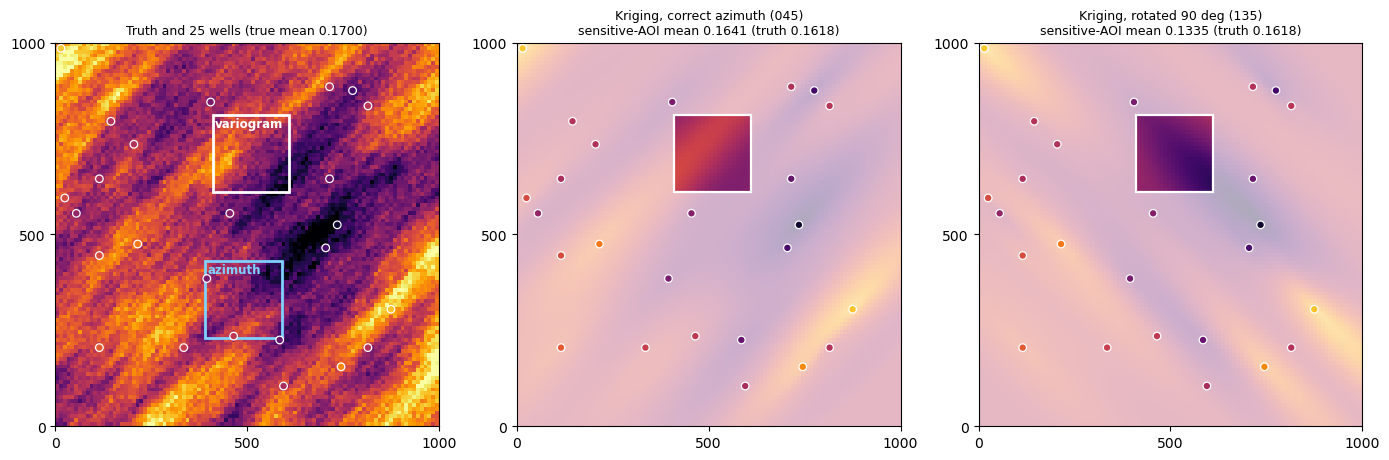

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
aoi.show(axes[0], phi, None, w, title=f'Truth and 25 wells (true mean {phi.mean():.4f})')
for a, col in zip(A[1:], ('white', '#7fd1ff')):
    x0, x1, y0, y1 = a.extent()
    axes[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=2))
    axes[0].text(x0 + 6, y1 - 30, a.name.split(', ')[1].split('-')[0], color=col, fontsize=8.5, fontweight='bold')
for ax, name in zip(axes[1:], DEMO[:2]):
    k = R['krig'][name]
    aoi.show(ax, k, sens, w, title=f'Kriging, {name}\nsensitive-AOI mean {sens.mean(k):.4f} (truth {sens.mean(phi):.4f})')
plt.tight_layout(); plt.show()

Kriging alone already shows the azimuth effect: the AOI sits between wells of very different porosity, and the
direction of continuity decides which of them the kriging weights favour.

## Three realizations per model (variogram-sensitive AOI)

Rows: variogram model. Columns: SGS realizations 1-3. The AOI is opaque; outside it is faded. The AOI mean porosity of
each realization is in its title.

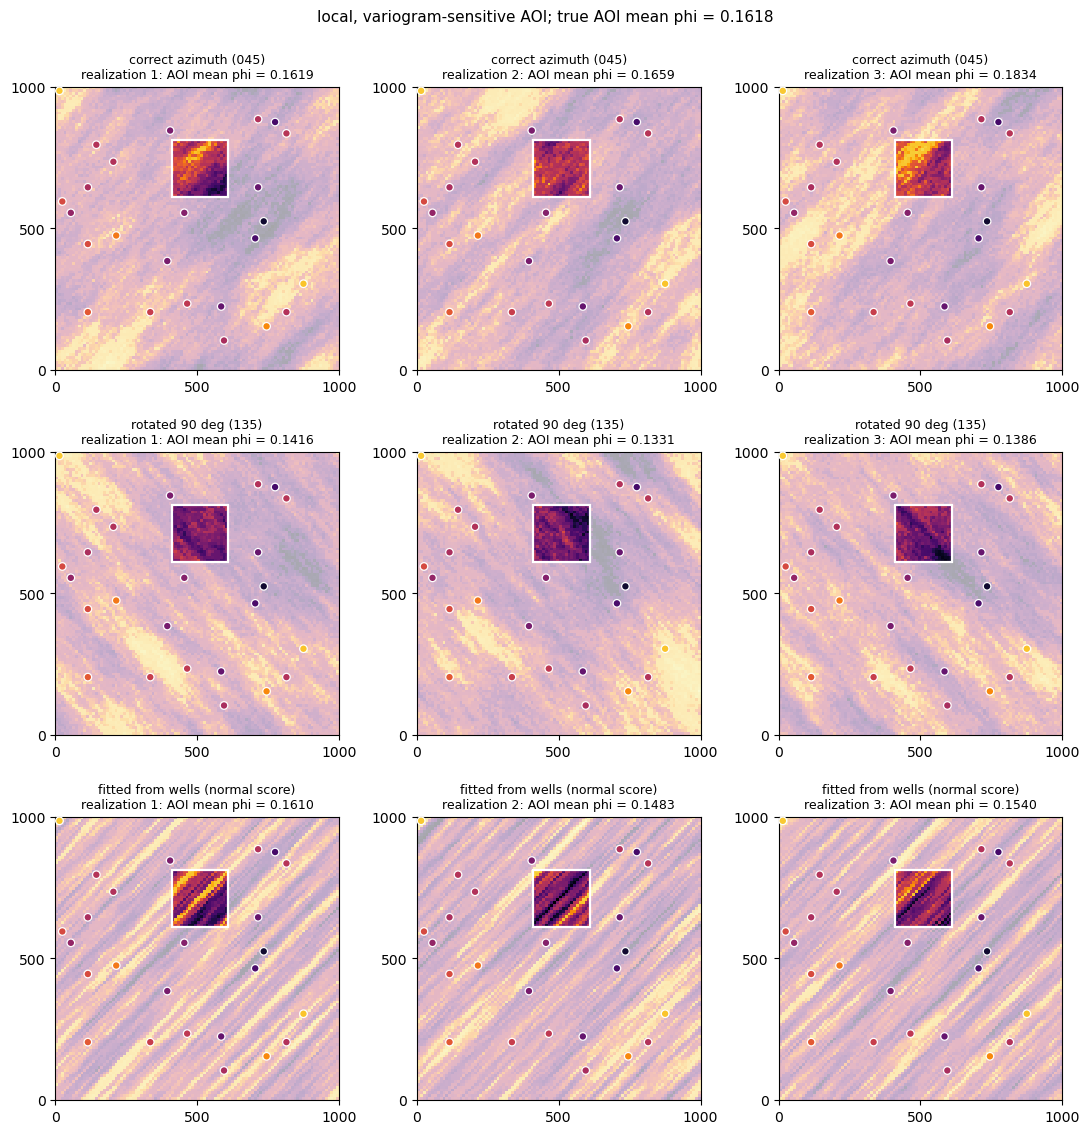

In [3]:
aoi.realization_grid(R, sens); plt.show()

The correct model's realizations bracket the true AOI average; the rotated model's are all low, because it
spreads the low wells to the north-west and south-east across the AOI instead of along the 045 trend. The model fitted
from 25 wells finds the right azimuth but its minor range sits at the 30 m minimum (too few short pairs across the
trend), so its realizations are thin streaks: a correct direction with a wrong range.

Same three models over the azimuth-insensitive AOI: a well inside the AOI pins the average, so rotating the
variogram changes little.

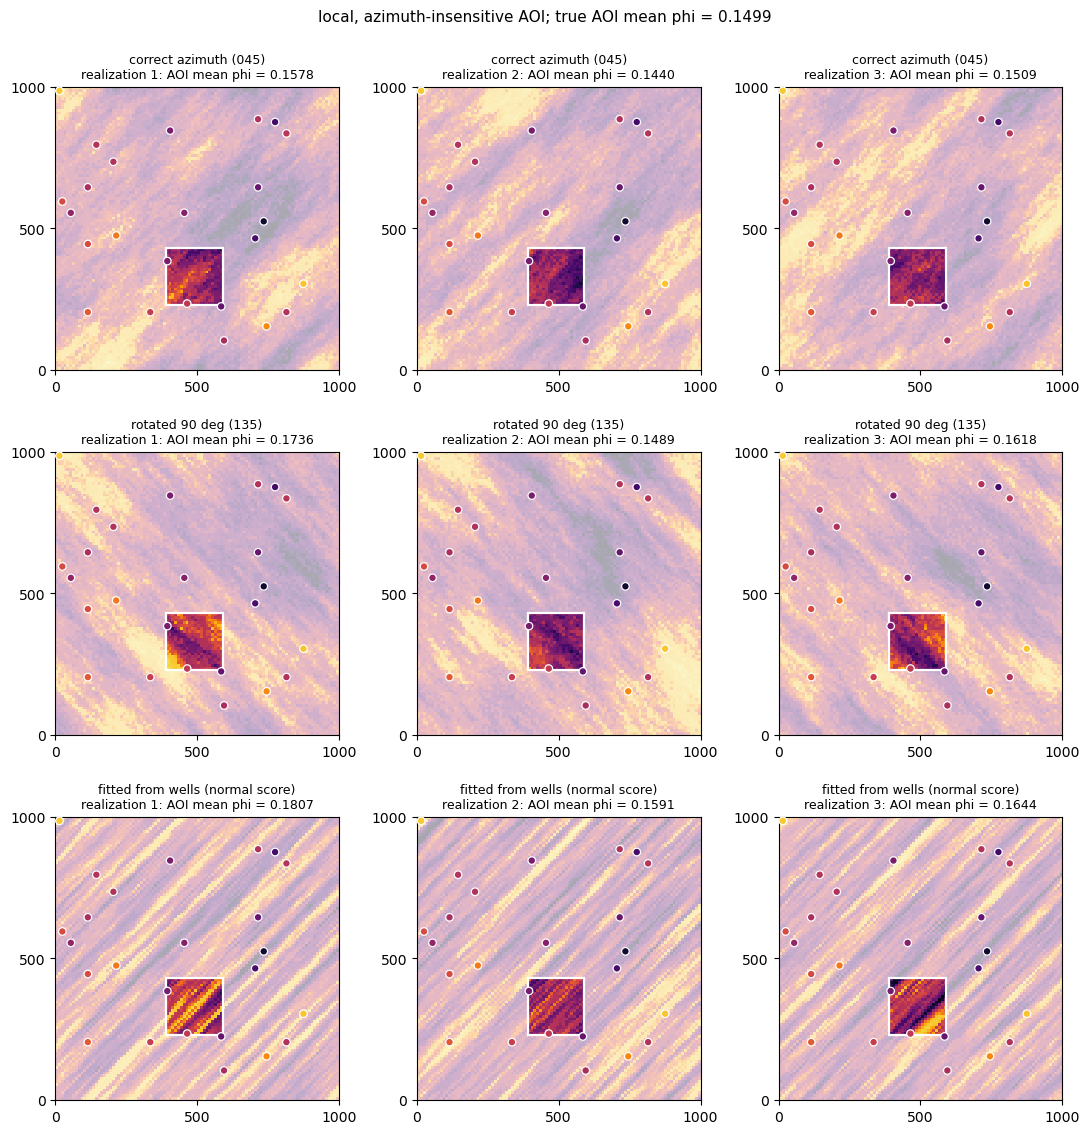

In [4]:
aoi.realization_grid(R, insens); plt.show()

## Distribution of the AOI mean over 100 realizations

Histograms of the AOI-average porosity per model. Dashed lines: the kriged AOI average of the same model. Black: truth.

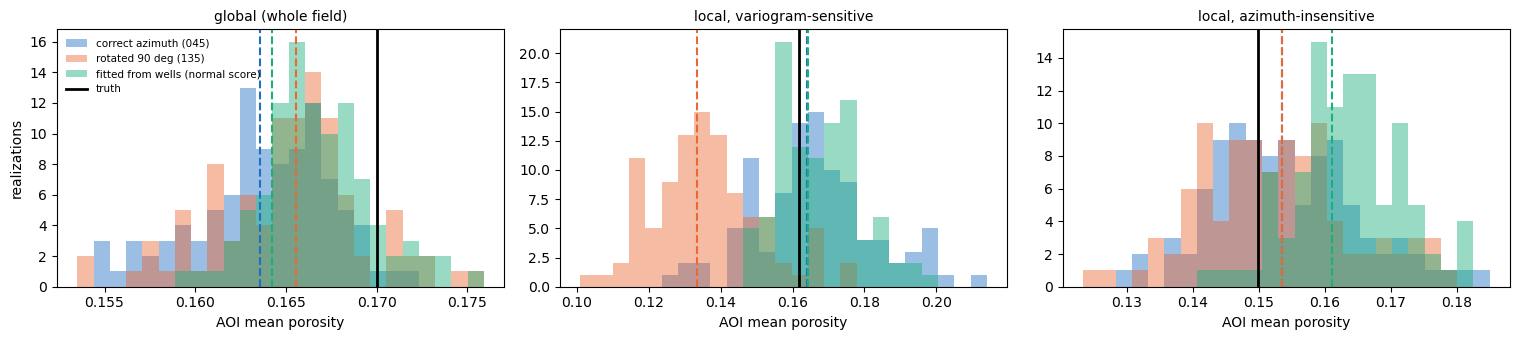

,aoi,truth_phi,krig_phi,sgs_mean_phi,sgs_sd_phi,p10_phi,p90_phi,truth_in_p10_p90,truth_ooip,krig_ooip,p10_ooip,p90_ooip
model,,,,,,,,,,,,
correct azimuth (045),global (whole field),0.1700,0.1635,0.1637,0.0037,0.1581,0.1681,False,9.7194,9.1258,8.7921,9.5566
correct azimuth (045),"local, variogram-sensitive",0.1618,0.1641,0.1660,0.0168,0.1466,0.1880,True,0.3632,0.3656,0.3170,0.4474
correct azimuth (045),"local, azimuth-insensitive",0.1499,0.1535,0.1540,0.0109,0.1422,0.1690,True,0.3258,0.3341,0.3030,0.3817
rotated 90 deg (135),global (whole field),0.1700,0.1655,0.1650,0.0041,0.1595,0.1706,True,9.7194,9.2799,8.8973,9.7813
rotated 90 deg (135),"local, variogram-sensitive",0.1618,0.1335,0.1363,0.0148,0.1181,0.1546,False,0.3632,0.2779,0.2386,0.3418
rotated 90 deg (135),"local, azimuth-insensitive",0.1499,0.1535,0.1524,0.0115,0.1401,0.1691,True,0.3258,0.3345,0.2967,0.3844
fitted from wells (normal score),global (whole field),0.1700,0.1642,0.1667,0.0030,0.1632,0.1703,True,9.7194,9.1470,9.2027,9.7375
fitted from wells (normal score),"local, variogram-sensitive",0.1618,0.1642,0.1674,0.0113,0.1540,0.1834,True,0.3632,0.3656,0.3397,0.4317
fitted from wells (normal score),"local, azimuth-insensitive",0.1499,0.1610,0.1635,0.0081,0.1524,0.1734,False,0.3258,0.3561,0.3354,0.3976


In [5]:
aoi.histograms(R); plt.show()
cols = ['aoi', 'truth_phi', 'krig_phi', 'sgs_mean_phi', 'sgs_sd_phi', 'p10_phi', 'p90_phi', 'truth_in_p10_p90', 'truth_ooip', 'krig_ooip', 'p10_ooip', 'p90_ooip']
S[S.model.isin(DEMO)].set_index('model')[cols]

Reading the table:

- *Kriging vs simulation.* For every model, the kriged AOI average is close to the mean of the 100 realization
  averages: kriging matches the expected value. Only simulation gives the spread (P10-P90).
- *Global AOI.* All models give nearly the same average; the variogram effect averages out. The remaining error is the
  sample mean of the 25 wells, which no variogram can fix, and the P10-P90 of a single well set can miss the truth.
- *Sensitive AOI.* The rotated model shifts the whole distribution; the correct model brackets the truth.

## All eight experimental variogram types

The same comparison for the model fitted with each variogram type (sorted by the kriged sensitive-AOI average).

In [6]:
t = S[S.model.str.startswith('type:')].pivot_table(index='model', columns='aoi', values=['krig_phi', 'p10_phi', 'p90_phi'])
t = t.reindex(columns=[a.name for a in A], level=1)
t.columns = [f'{v} | {a.split(",")[-1].strip()}' for v, a in t.columns]
t = t.sort_values(t.columns[1])
display(t.round(4))
spread = S[S.model.str.startswith('type:')].groupby('aoi').krig_phi.agg(lambda s: s.max() - s.min())
rot = S[S.model == DEMO[0]].set_index('aoi').krig_phi - S[S.model == DEMO[1]].set_index('aoi').krig_phi
pd.DataFrame({'range of kriged AOI mean across 8 types': spread, 'correct minus rotated (045 - 135)': rot}).reindex([a.name for a in A]).round(4)

,krig_phi | global (whole field),krig_phi | variogram-sensitive,krig_phi | azimuth-insensitive,p10_phi | global (whole field),p10_phi | variogram-sensitive,p10_phi | azimuth-insensitive,p90_phi | global (whole field),p90_phi | variogram-sensitive,p90_phi | azimuth-insensitive
model,,,,,,,,,
type: semivariogram,0.1665,0.1435,0.1435,0.1616,0.1323,0.1334,0.1696,0.1633,0.1548
type: general_relative,0.1662,0.1457,0.1426,0.1601,0.1267,0.1319,0.1702,0.1639,0.1562
type: log,0.1664,0.1460,0.1421,0.1610,0.1285,0.1349,0.1703,0.1623,0.1523
type: pairwise_relative,0.1665,0.1476,0.1417,0.1608,0.1318,0.1318,0.1710,0.1638,0.1555
type: cumulative,0.1680,0.1543,0.1501,0.1621,0.1331,0.1375,0.1726,0.1745,0.1640
type: normal_score,0.1642,0.1642,0.1610,0.1628,0.1525,0.1514,0.1701,0.1800,0.1751
type: rodogram,0.1660,0.1643,0.1649,0.1632,0.1528,0.1560,0.1717,0.1786,0.1780
type: correlogram,0.1660,0.1643,0.1650,0.1644,0.1514,0.1553,0.1710,0.1806,0.1815


,range of kriged AOI mean across 8 types,correct minus rotated (045 - 135)
aoi,,
global (whole field),0.0038,-0.0020
"local, variogram-sensitive",0.0209,0.0306
"local, azimuth-insensitive",0.0233,-0.0000


## Variogram range and ergodic fluctuations

Standard deviation of the whole-field average porosity over 100 realizations, for isotropic models of increasing range.
Unconditional (no wells): the larger the range, the fewer independent "blobs" fit in the field, so the field average
fluctuates more. Conditioned on 25 wells, the data pin down much of that fluctuation.

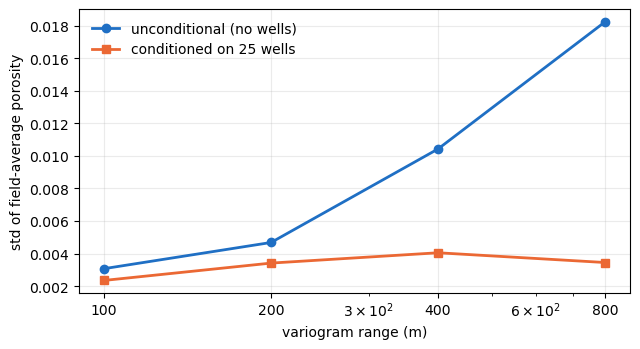

,uncond_sd_phi,sgs_sd_phi
range_m,,
100.0,0.0031,0.0023
200.0,0.0047,0.0034
400.0,0.0104,0.0040
800.0,0.0182,0.0034


In [7]:
iso = S[S.model.str.startswith('isotropic') & (S.aoi == glob.name)].copy()
iso['range_m'] = iso.model.str.extract(r'(\d+)').astype(float)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(iso.range_m, iso.uncond_sd_phi, 'o-', color='#1f6fc4', lw=2, label='unconditional (no wells)')
ax.plot(iso.range_m, iso.sgs_sd_phi, 's-', color='#eb6834', lw=2, label='conditioned on 25 wells')
ax.set_xscale('log'); ax.set_xticks(aoi.RANGES); ax.set_xticklabels([f'{r:.0f}' for r in aoi.RANGES])
ax.set_xlabel('variogram range (m)'); ax.set_ylabel('std of field-average porosity'); ax.legend(frameon=False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
iso.set_index('range_m')[['uncond_sd_phi', 'sgs_sd_phi']]

## Summary

In [8]:
d = S.set_index(['model', 'aoi'])
k = lambda m, a: d.loc[(m, a.name), 'krig_phi']
o = lambda m, a: d.loc[(m, a.name), 'krig_ooip']
print(f"Sensitive AOI: correct (045) kriged mean {k(DEMO[0], sens):.4f}, rotated (135) {k(DEMO[1], sens):.4f}, truth {sens.mean(phi):.4f}; "
      f"OOIP {o(DEMO[0], sens):.3f} vs {o(DEMO[1], sens):.3f} MMSTB ({100 * (o(DEMO[1], sens) / o(DEMO[0], sens) - 1):+.0f}%).")
print(f"Azimuth-insensitive AOI: correct {k(DEMO[0], insens):.4f}, rotated {k(DEMO[1], insens):.4f}, truth {insens.mean(phi):.4f}.")
print(f"Global AOI: kriged means across all {len(R['models'])} models {d.xs(glob.name, level='aoi').krig_phi.min():.4f}-{d.xs(glob.name, level='aoi').krig_phi.max():.4f} "
      f"(truth {phi.mean():.4f}, well mean {w['v'].mean():.4f}).")
print(f"8 variogram types on the sensitive AOI: kriged means {spread[sens.name]:.4f} apart; on the global AOI {spread[glob.name]:.4f} apart.")
print(f"Unconditional std of the field average grows {iso.uncond_sd_phi.iloc[-1] / iso.uncond_sd_phi.iloc[0]:.1f}x from 100 m to 800 m range.")

Sensitive AOI: correct (045) kriged mean 0.1641, rotated (135) 0.1335, truth 0.1618; OOIP 0.366 vs 0.278 MMSTB (-24%).
Azimuth-insensitive AOI: correct 0.1535, rotated 0.1535, truth 0.1499.
Global AOI: kriged means across all 15 models 0.1635-0.1680 (truth 0.1700, well mean 0.1654).
8 variogram types on the sensitive AOI: kriged means 0.0209 apart; on the global AOI 0.0038 apart.
Unconditional std of the field average grows 5.9x from 100 m to 800 m range.
